In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("titanic.csv")

In [83]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare
407,408,1,2,"Richards, Master. William Rowe",male,3.0,1,1,29106,18.7500,Unknown,S,"Southampton, England",0,3,6.2500
183,184,1,2,"Becker, Master. Richard F",male,1.0,2,1,230136,39.0000,F4,S,"Southampton, England",0,4,9.7500
696,697,0,3,"Kelly, Mr. James",male,44.0,0,0,363592,8.0500,Unknown,S,"Southampton, England",1,1,8.0500
628,629,0,3,"Bostandyeff, Mr. Guentcho",male,26.0,0,0,349224,7.8958,Unknown,S,"Southampton, England",1,1,7.8958
59,60,0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9000,Unknown,S,"Southampton, England",0,8,5.8625


In [4]:
df["Embarked"].unique()

array(['S', 'C', 'Q', nan], dtype=object)

The 3 Departure Stations

Southampton, England

Cherbourg, France

Queenstown (Cobh), Ireland

In [5]:
#Lets Add This Column for more Info
df["Departure_Station"] = df["Embarked"].map({"S": "Southampton, England", "C": "Cherbourg, France", "Q": "Queenstown , Ireland"})

In [6]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station
521,522,0,3,"Vovk, Mr. Janko",male,22.0,0,0,349252,7.8958,NaN,S,"Southampton, England"
487,488,0,1,"Kent, Mr. Edward Austin",male,58.0,0,0,11771,29.7000,B37,C,"Cherbourg, France"
574,575,0,3,"Rush, Mr. Alfred George John",male,16.0,0,0,A/4. 20589,8.0500,NaN,S,"Southampton, England"
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S,"Southampton, England"
238,239,0,2,"Pengelly, Mr. Frederick William",male,19.0,0,0,28665,10.5000,NaN,S,"Southampton, England"


In [7]:
df.shape

(891, 13)

In [8]:
len(df)

891

In [9]:
df.value_counts().sum()

183

In [10]:
df.isnull().sum()

PassengerId            0
Survived               0
Pclass                 0
Name                   0
Sex                    0
Age                  177
SibSp                  0
Parch                  0
Ticket                 0
Fare                   0
Cabin                687
Embarked               2
Departure_Station      2
dtype: int64

In [12]:
df["Pclass"].unique()

array([3, 1, 2], dtype=int64)

In [13]:
# Lets Deal with the Cabin Column
df[df["Pclass"] == 1]["Cabin"].unique()

array(['C85', 'C123', 'E46', 'C103', 'A6', 'C23 C25 C27', nan, 'B78',
       'D33', 'B30', 'C52', 'B28', 'C83', 'E31', 'A5', 'D10 D12', 'D26',
       'C110', 'B58 B60', 'D47', 'B86', 'C2', 'E33', 'B19', 'A7', 'C49',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'C22 C26', 'C106', 'C65', 'E36', 'C54', 'B57 B59 B63 B66',
       'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40', 'T', 'C128',
       'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E44', 'A34', 'C104',
       'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14', 'B37', 'C30',
       'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38', 'B39', 'B22',
       'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68', 'B41', 'A20',
       'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48', 'E58', 'C126',
       'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'C62 C64', 'E24', 'C90',
       'C45', 'E8', 'B101', 'D45', 'C46', 'D30', 'D11', 'B3', 'D6',
       'B8

In [14]:
# Lets Deal with the Cabin Column
df[df["Pclass"] == 2]["Cabin"].unique()

array([nan, 'D56', 'F33', 'E101', 'F2', 'F4', 'D', 'E77'], dtype=object)

In [15]:
df[df["Pclass"] == 3]["Cabin"].unique()

array([nan, 'G6', 'F G73', 'F E69', 'E10', 'F G63', 'E121', 'F38'],
      dtype=object)

In [16]:
len(df[df["Pclass"] == 1])

216

In [17]:
len(df[df["Pclass"] == 2])

184

In [18]:
len(df[df["Pclass"] == 3])

491

In [19]:
import seaborn as sns

<Axes: xlabel='Pclass', ylabel='Count'>

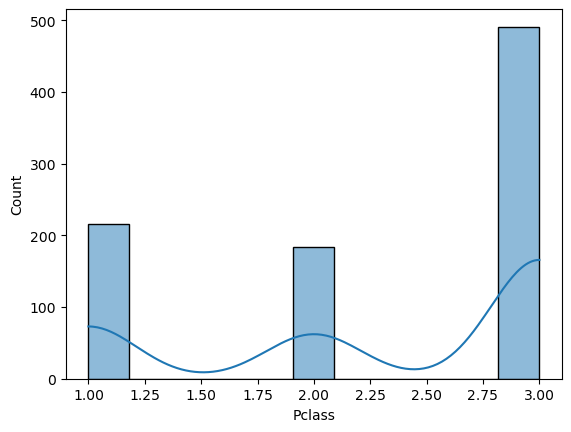

In [20]:
sns.histplot(data=df, x="Pclass", kde=True)

In [21]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [22]:
df["Age"].isnull().sum()

177

In [23]:
#Lets Drop The Null Values from Age
df.dropna(subset=["Age"], inplace=True)

In [24]:
len(df)

714

In [25]:
#We Cant Treat Cabin Like This, But We May Find Some valueable Info From it
df["Cabin"].isnull().sum()

529

In [26]:
df["Cabin"].fillna("Unknown", inplace=True)

C:\Users\aitza\AppData\Local\Temp\ipykernel_12176\1472048659.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Cabin"].fillna("Unknown", inplace=True)


In [27]:
df.isnull().sum()

PassengerId          0
Survived             0
Pclass               0
Name                 0
Sex                  0
Age                  0
SibSp                0
Parch                0
Ticket               0
Fare                 0
Cabin                0
Embarked             2
Departure_Station    2
dtype: int64

In [28]:
df["Departure_Station"].fillna("Unknown", inplace=True)

C:\Users\aitza\AppData\Local\Temp\ipykernel_12176\448174163.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Departure_Station"].fillna("Unknown", inplace=True)


In [29]:
df["Embarked"].fillna("Unknown", inplace=True)

C:\Users\aitza\AppData\Local\Temp\ipykernel_12176\1232196710.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Embarked"].fillna("Unknown", inplace=True)


In [30]:
df.isnull().sum()

PassengerId          0
Survived             0
Pclass               0
Name                 0
Sex                  0
Age                  0
SibSp                0
Parch                0
Ticket               0
Fare                 0
Cabin                0
Embarked             0
Departure_Station    0
dtype: int64

In [31]:
#Let Us Check The Dupes
df.duplicated().sum()

0

In [32]:
# Lets get Aquanted Witg Corolattions
df_numeric = df.select_dtypes(include=np.number)

In [67]:
df["Pclass"].unique()

array([3, 1, 2], dtype=int64)

In [33]:
df_numeric.corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,0.029340,-0.035349,0.036847,-0.082398,-0.011617,0.009592
Survived,0.029340,1.000000,-0.359653,-0.077221,-0.017358,0.093317,0.268189
Pclass,-0.035349,-0.359653,1.000000,-0.369226,0.067247,0.025683,-0.554182
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.082398,-0.017358,0.067247,-0.308247,1.000000,0.383820,0.138329
Parch,-0.011617,0.093317,0.025683,-0.189119,0.383820,1.000000,0.205119
Fare,0.009592,0.268189,-0.554182,0.096067,0.138329,0.205119,1.000000


<Axes: >

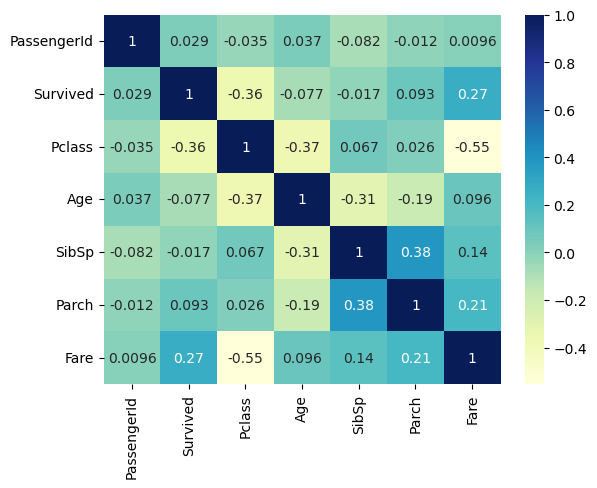

In [72]:
sns.heatmap(df_numeric.corr(), annot=True, cmap="YlGnBu")

<Axes: xlabel='Pclass', ylabel='Fare'>

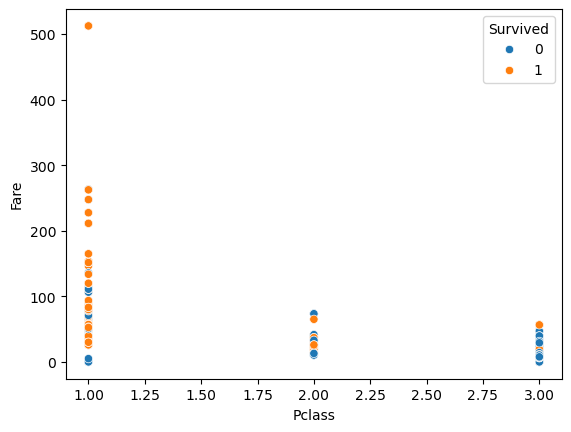

In [35]:
sns.scatterplot(data=df, x="Pclass", y="Fare", hue="Survived")

<Axes: xlabel='Parch', ylabel='Fare'>

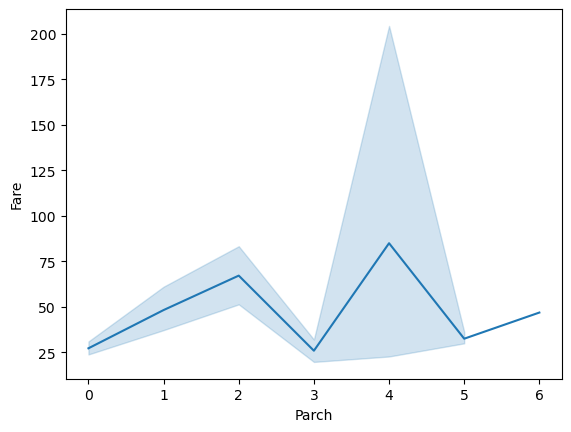

In [36]:
sns.lineplot(data=df, x="Parch", y="Fare")

<Axes: xlabel='SibSp', ylabel='Fare'>

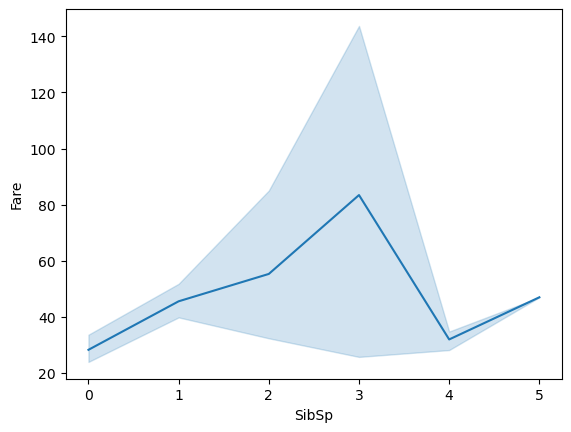

In [37]:
sns.lineplot(data=df, x="SibSp", y="Fare")

In [38]:
df[df["SibSp"] == 3][["Pclass", "Name", "Fare"]]

,Pclass,Name,Fare
7,3,"Palsson, Master. Gosta Leonard",21.075
24,3,"Palsson, Miss. Torborg Danira",21.075
27,1,"Fortune, Mr. Charles Alexander",263.000
63,3,"Skoog, Master. Harald",27.900
85,3,"Backstrom, Mrs. Karl Alfred (Maria Mathilda Gu...",15.850
88,1,"Fortune, Miss. Mabel Helen",263.000
341,1,"Fortune, Miss. Alice Elizabeth",263.000
374,3,"Palsson, Miss. Stina Viola",21.075
634,3,"Skoog, Miss. Mabel",27.900
642,3,"Skoog, Miss. Margit Elizabeth",27.900


In [39]:
df[df["SibSp"] == 4][["Pclass", "Name", "Fare"]]

,Pclass,Name,Fare
16,3,"Rice, Master. Eugene",29.1250
50,3,"Panula, Master. Juha Niilo",39.6875
68,3,"Andersson, Miss. Erna Alexandra",7.9250
119,3,"Andersson, Miss. Ellis Anna Maria",31.2750
164,3,"Panula, Master. Eino Viljami",39.6875
171,3,"Rice, Master. Arthur",29.1250
182,3,"Asplund, Master. Clarence Gustaf Hugo",31.3875
233,3,"Asplund, Miss. Lillian Gertrud",31.3875
261,3,"Asplund, Master. Edvin Rojj Felix",31.3875
266,3,"Panula, Mr. Ernesti Arvid",39.6875


In [40]:
df[df["Parch"] == 4][["Pclass", "Name", "Fare"]]

,Pclass,Name,Fare
167,3,"Skoog, Mrs. William (Anna Bernhardina Karlsson)",27.900
360,3,"Skoog, Mr. Wilhelm",27.900
438,1,"Fortune, Mr. Mark",263.000
567,3,"Palsson, Mrs. Nils (Alma Cornelia Berglund)",21.075


In [41]:
df[df["Parch"] == 3][["Pclass", "Name", "Fare"]]

,Pclass,Name,Fare
86,3,"Ford, Mr. William Neal",34.3750
437,2,"Richards, Mrs. Sidney (Emily Hocking)",18.7500
736,3,"Ford, Mrs. Edward (Margaret Ann Watson)",34.3750
774,2,"Hocking, Mrs. Elizabeth (Eliza Needs)",23.0000
858,3,"Baclini, Mrs. Solomon (Latifa Qurban)",19.2583


In [ ]:
df[df["Parch"] == 5][["Age", "Pclass"]]

In [73]:
df[df["Parch"] == 5][["Pclass", "Name", "Fare"]]

,Pclass,Name,Fare
13,3,"Andersson, Mr. Anders Johan",31.2750
25,3,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",31.3875
610,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",31.2750
638,3,"Panula, Mrs. Juha (Maria Emilia Ojala)",39.6875
885,3,"Rice, Mrs. William (Margaret Norton)",29.1250


In [42]:
#Lets Find Fare And Survival Rate Comparison
df[df["Survived"] == 1]["Fare"].mean()

51.843205172413796

In [43]:
df[df["Survived"] == 0]["Fare"].mean()

22.96545636792453

In [80]:
df["Parch"].sample(5)

400    0
385    0
11     0
743    0
162    0
Name: Parch, dtype: int64

In [76]:
df["SibSp"].sample(5)

69     2
167    1
743    1
810    0
682    0
Name: SibSp, dtype: int64

In [86]:
df2 = pd.read_csv("titanic.csv")

In [87]:
df2.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [89]:
df2["PassengerId"] = df2["PassengerId"].astype("float64")

In [90]:
df2.dtypes

PassengerId    float64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [84]:
df.dtypes

PassengerId            int64
Survived               int64
Pclass                 int64
Name                  object
Sex                   object
Age                  float64
SibSp                  int64
Parch                  int64
Ticket                object
Fare                 float64
Cabin                 object
Embarked              object
Departure_Station     object
Travel_Alone           int32
Family_Count           int64
Individual_Fare      float64
dtype: object

In [44]:
#lets add more Data, (Feature Engineering)
df["Travel_Alone"] = ((df["SibSp"] + df["Parch"]) == 0).astype(int)

In [45]:
df[["Travel_Alone", "Parch", "SibSp"]].sample(10)

,Travel_Alone,Parch,SibSp
684,0,1,1
177,1,0,0
827,0,2,0
143,1,0,0
116,1,0,0
842,1,0,0
35,0,0,1
763,0,2,1
247,0,2,0
810,1,0,0


In [46]:
# The fare of Individuals is Missing
df["Family_Count"] = df["SibSp"] + df["Parch"]

In [47]:
df["Family_Count"] = df["Family_Count"] + 1

In [48]:
df[["Family_Count", "Parch", "SibSp"]].sample(10)

,Family_Count,Parch,SibSp
348,3,1,1
51,1,0,0
322,1,0,0
595,3,1,1
210,1,0,0
700,2,0,1
44,1,0,0
616,3,1,1
834,1,0,0
780,1,0,0


In [49]:
df["Individual_Fare"] = df["Fare"] / df["Family_Count"]

In [50]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare
150,151,0,2,"Bateman, Rev. Robert James",male,51.0,0,0,S.O.P. 1166,12.5250,Unknown,S,"Southampton, England",1,1,12.5250
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,"Southampton, England",1,1,8.0500
484,485,1,1,"Bishop, Mr. Dickinson H",male,25.0,1,0,11967,91.0792,B49,C,"Cherbourg, France",0,2,45.5396
195,196,1,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,B80,C,"Cherbourg, France",1,1,146.5208
816,817,0,3,"Heininen, Miss. Wendla Maria",female,23.0,0,0,STON/O2. 3101290,7.9250,Unknown,S,"Southampton, England",1,1,7.9250


In [51]:
df.isnull().sum()

PassengerId          0
Survived             0
Pclass               0
Name                 0
Sex                  0
Age                  0
SibSp                0
Parch                0
Ticket               0
Fare                 0
Cabin                0
Embarked             0
Departure_Station    0
Travel_Alone         0
Family_Count         0
Individual_Fare      0
dtype: int64

In [52]:
df[df["Pclass"] == 1]["Individual_Fare"].mean()

53.34933189964158

In [53]:
df[df["Pclass"] == 2]["Individual_Fare"].mean()

13.001864450867053

In [54]:
df[df["Pclass"] == 3]["Individual_Fare"].mean()

7.751575278336687

In [55]:
df.to_excel("titanic_modified.xlsx", index=False)

In [58]:
#One Hot Encoding
one_hot = pd.get_dummies(df["Departure_Station"], prefix="Station", drop_first=True)


In [59]:
one_hot

,"Station_Queenstown , Ireland","Station_Southampton, England",Station_Unknown
0,False,True,False
1,False,False,False
2,False,True,False
3,False,True,False
4,False,True,False
...,...,...,...
885,True,False,False
886,False,True,False
887,False,True,False
889,False,False,False


In [60]:
df_encoded = pd.concat([df, one_hot], axis=1)

In [61]:
df_encoded.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Station_Unknown
172,173,1,3,"Johnson, Miss. Eleanor Ileen",female,1.0,1,1,347742,11.1333,Unknown,S,"Southampton, England",0,3,3.7111,False,True,False
108,109,0,3,"Rekic, Mr. Tido",male,38.0,0,0,349249,7.8958,Unknown,S,"Southampton, England",1,1,7.8958,False,True,False
641,642,1,1,"Sagesser, Mlle. Emma",female,24.0,0,0,PC 17477,69.3000,B35,C,"Cherbourg, France",1,1,69.3000,False,False,False
408,409,0,3,"Birkeland, Mr. Hans Martin Monsen",male,21.0,0,0,312992,7.7750,Unknown,S,"Southampton, England",1,1,7.7750,False,True,False
206,207,0,3,"Backstrom, Mr. Karl Alfred",male,32.0,1,0,3101278,15.8500,Unknown,S,"Southampton, England",0,2,7.9250,False,True,False


In [62]:
one_hot_gender = pd.get_dummies(df["Sex"], prefix="Gender", drop_first=True)

In [63]:
one_hot_gender

,Gender_male
0,True
1,False
2,False
3,False
4,True
...,...
885,False
886,True
887,False
889,True


In [64]:
df_encoded = pd.concat([df_encoded, one_hot_gender], axis=1)

In [65]:
df_encoded

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Station_Unknown,Gender_male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,"Southampton, England",0,2,3.625000,False,True,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,"Cherbourg, France",0,2,35.641650,False,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,"Southampton, England",1,1,7.925000,False,True,False,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,"Southampton, England",0,2,26.550000,False,True,False,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,"Southampton, England",1,1,8.050000,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,Unknown,Q,"Queenstown , Ireland",0,6,4.854167,True,False,False,False
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,Unknown,S,"Southampton, England",1,1,13.000000,False,True,False,True
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,"Southampton, England",1,1,30.000000,False,True,False,False
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,"Cherbourg, France",1,1,30.000000,False,False,False,True
